In [1]:
# Aim: To perform and analyze Classification Algorithms (Logistic Regression, KNN, SVM, Decision Tree, Random Forest) on Heart Disease Dataset
# Student Details
# Name : Vaishnavi Chaudhari
# Roll no : 11
# Sec : C
# Subject : DSS

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import os

In [4]:
os.getcwd()

'C:\\Users\\Vaishnavi\\Downloads\\DSS'

In [5]:
try:
    os.chdir(r'C:\Users\Vaishnavi\Downloads\DSS')
except Exception:
    pass

In [6]:
try:
    data = pd.read_csv('heart.csv')
except FileNotFoundError:
    data = pd.read_csv(r'C:\Users\Vaishnavi\Downloads\DSS\heart.csv')

In [7]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [8]:
data.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [10]:
data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [11]:
data.shape

(303, 14)

In [12]:
data.size

4242

In [13]:
data.ndim

2

In [14]:
# Data Preprocessing & Missing Value Check
# Check missing values
data.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [15]:
data.isna().any()

age         False
sex         False
cp          False
trestbps    False
chol        False
fbs         False
restecg     False
thalach     False
exang       False
oldpeak     False
slope       False
ca          False
thal        False
target      False
dtype: bool

In [16]:
# Feature Extraction & Train-Test Split
x = data.drop('target', axis=1)
y = data['target']

In [17]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [18]:
# 1. Logistic Regression Classifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

In [19]:
log = LogisticRegression(max_iter=2000, random_state=42)
log.fit(x_train, y_train)

LogisticRegression(max_iter=2000, random_state=42)

In [20]:
y_pred = log.predict(x_test)

In [21]:
acc_lr = accuracy_score(y_test, y_pred)
acc_lr

0.8852459016393442

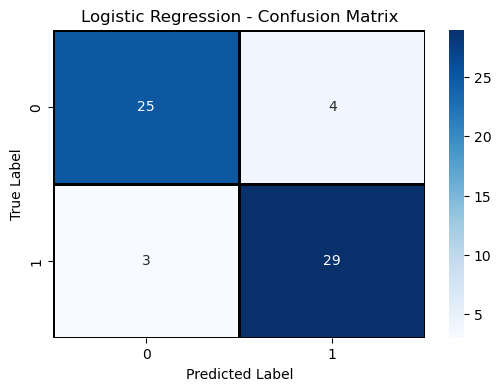

In [22]:
cm = confusion_matrix(y_test, y_pred)
labels = np.unique(y_test)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', linewidths=1, linecolor='black')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [23]:
# 2. K-Nearest Neighbors (KNN) Classifier
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(x_train, y_train)

KNeighborsClassifier()

In [24]:
y_pred2 = knn.predict(x_test)

In [25]:
acc_knn = accuracy_score(y_test, y_pred2)
acc_knn

0.6885245901639344

In [26]:
# 3. Support Vector Machine (SVM / SVC)
from sklearn.svm import SVC

svm_model = SVC(random_state=42)
svm_model.fit(x_train, y_train)

SVC(random_state=42)

In [27]:
y_pred3 = svm_model.predict(x_test)

In [28]:
acc_svm = accuracy_score(y_test, y_pred3)
acc_svm

0.7049180327868853

In [29]:
# 4. Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_train, y_train)

DecisionTreeClassifier(random_state=42)

In [30]:
y_pred4 = dt.predict(x_test)

In [31]:
acc_dt = accuracy_score(y_test, y_pred4)
print('Accuracy without pruning:', acc_dt)
acc_dt

Accuracy without pruning: 0.7540983606557377


0.7540983606557377

In [32]:
dt_depth = DecisionTreeClassifier(max_depth=12, random_state=42)
dt_depth.fit(x_train, y_train)
y_pred_depth = dt_depth.predict(x_test)
acc_dt_pruned = accuracy_score(y_test, y_pred_depth)
print('Accuracy with max_depth pruning:', acc_dt_pruned)
acc_dt_pruned

Accuracy with max_depth pruning: 0.7540983606557377


0.7540983606557377

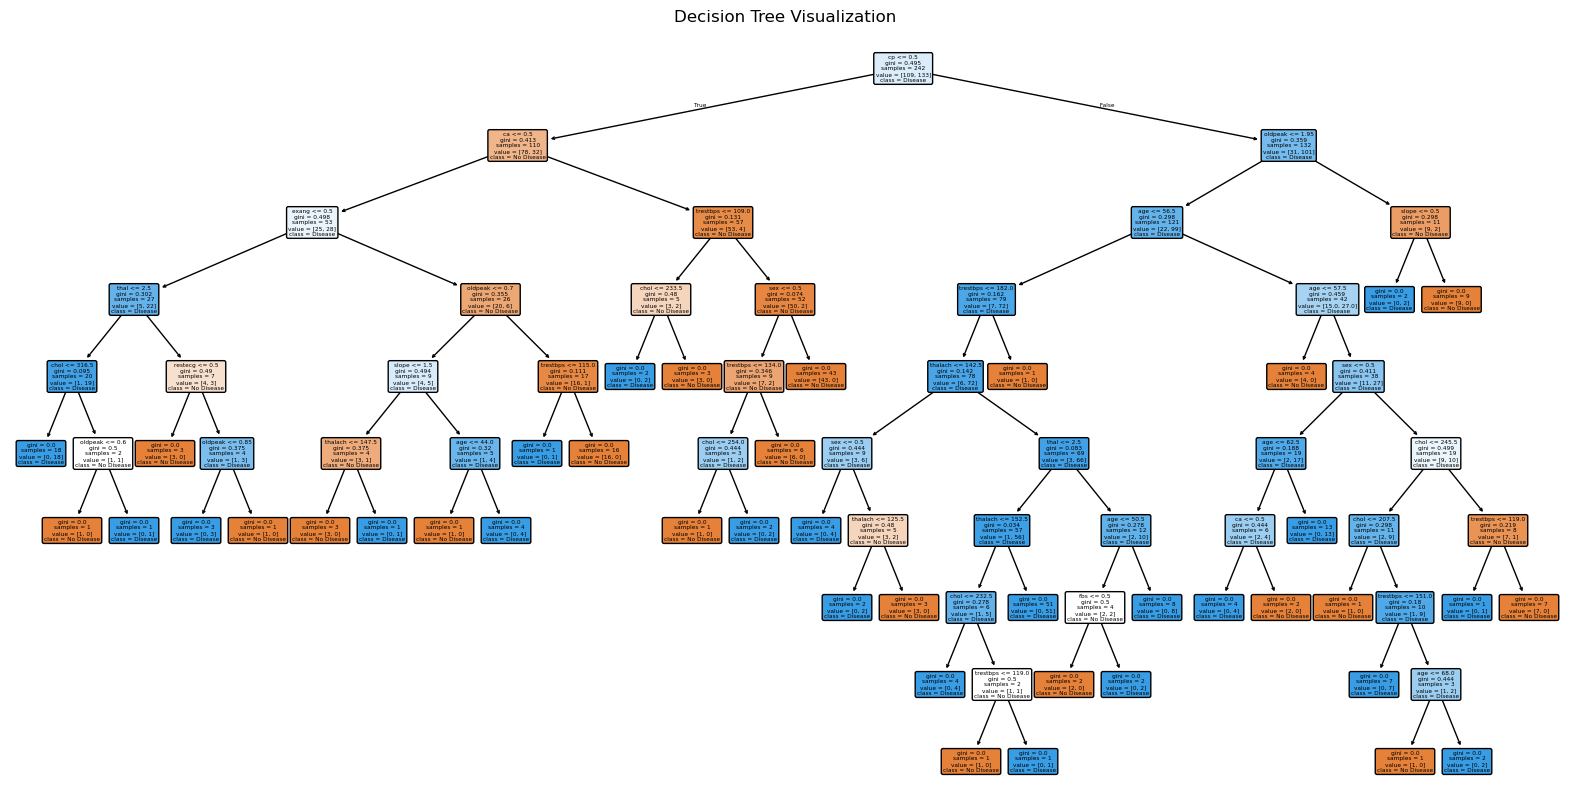

In [33]:
plt.figure(figsize=(20, 10))
tree.plot_tree(
    dt,
    feature_names=x.columns,
    class_names=['No Disease', 'Disease'],
    filled=True,
    rounded=True
)
plt.title('Decision Tree Visualization')
plt.show()

In [34]:
# 5. Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(x_train, y_train)

RandomForestClassifier(random_state=42)

In [35]:
y_pred5 = rf.predict(x_test)

In [36]:
acc_rf = accuracy_score(y_test, y_pred5)
acc_rf

0.8360655737704918

In [37]:
# 6. Model Benchmark & Comparison Summary
benchmark_df = pd.DataFrame({
    'Classification Algorithm': [
        'Logistic Regression',
        'K-Nearest Neighbors (KNN)',
        'Support Vector Machine (SVM)',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy Score': [acc_lr, acc_knn, acc_svm, acc_dt, acc_rf]
})
benchmark_df

,Classification Algorithm,Accuracy Score
0,Logistic Regression,0.885246
1,K-Nearest Neighbors (KNN),0.688525
2,Support Vector Machine (SVM),0.704918
3,Decision Tree,0.754098
4,Random Forest,0.836066
